# LAB 1 - Bài 2 (Trang 15-17): Phân tích dữ liệu Titanic
SV: Hồng Kim Dung - 6451071009

In [1]:
# linear algebra
import numpy as np
# data processing
import pandas as pd
# data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Hồng Kim Dung - 6451071009")
with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})
df.head(12)

Hồng Kim Dung - 6451071009


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,NaN,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,NaN,C,NaN,22.0,"Montevideo, Uruguay"


## Câu 1: Nhập dữ liệu và thống kê thông tin cơ bản của các thuộc tính

In [2]:
print("Hồng Kim Dung - 6451071009")

print("Kích thước:", df.shape)
df.info()

Hồng Kim Dung - 6451071009
Kích thước: (1309, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB


In [3]:
print("Hồng Kim Dung - 6451071009")
df.describe(include="all").T

Hồng Kim Dung - 6451071009


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pclass,1309.0,NaN,NaN,NaN,2.294882,0.837836,1.0,2.0,3.0,3.0,3.0
survived,1309.0,NaN,NaN,NaN,0.381971,0.486055,0.0,0.0,0.0,1.0,1.0
name,1309,1307,"Kelly, Mr. James",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,1309,2,male,843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1046.0,NaN,NaN,NaN,29.881135,14.4135,0.1667,21.0,28.0,39.0,80.0
sibsp,1309.0,NaN,NaN,NaN,0.498854,1.041658,0.0,0.0,0.0,1.0,8.0
parch,1309.0,NaN,NaN,NaN,0.385027,0.86556,0.0,0.0,0.0,0.0,9.0
ticket,1309,929,CA. 2343,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fare,1308.0,NaN,NaN,NaN,33.295479,51.758668,0.0,7.8958,14.4542,31.275,512.3292
cabin,295,186,C23 C25 C27,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Câu 2: 5 thuộc tính có nhiều giá trị rỗng nhất

In [4]:
print("Hồng Kim Dung - 6451071009")
null_cnt = df.isnull().sum().sort_values(ascending=False)
top5 = pd.DataFrame({"so_gia_tri_rong": null_cnt, "ty_le_%": (null_cnt/len(df)*100).round(2)}).head(5)
top5

Hồng Kim Dung - 6451071009


,so_gia_tri_rong,ty_le_%
body,1188,90.76
cabin,1014,77.46
boat,823,62.87
home.dest,564,43.09
age,263,20.09


Hồng Kim Dung - 6451071009


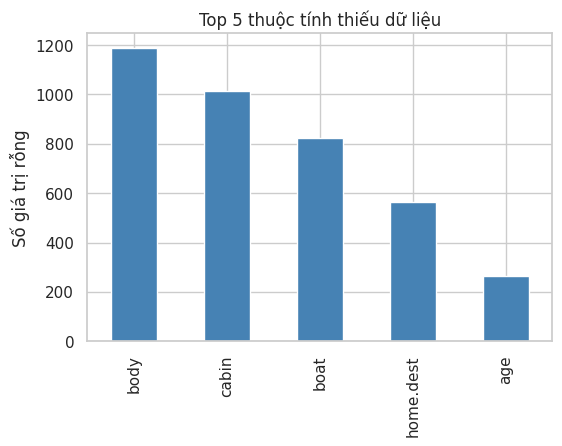

In [5]:
print("Hồng Kim Dung - 6451071009")
top5["so_gia_tri_rong"].plot(kind="bar", color="steelblue", figsize=(6,4), title="Top 5 thuộc tính thiếu dữ liệu")
plt.ylabel("Số giá trị rỗng"); plt.show()

**Nhận xét:** các thuộc tính `body`, `cabin`, `boat`, `home.dest`, `age` thiếu nhiều nhất (xem bảng trên). `body`, `cabin`, `boat` thiếu rất nhiều nên gần như không dùng được để dự đoán; `age` thiếu ít hơn nên có thể điền giá trị.

## Câu 3: Liên quan giữa tuổi (age), giới tính (sex) và survived

Hồng Kim Dung - 6451071009


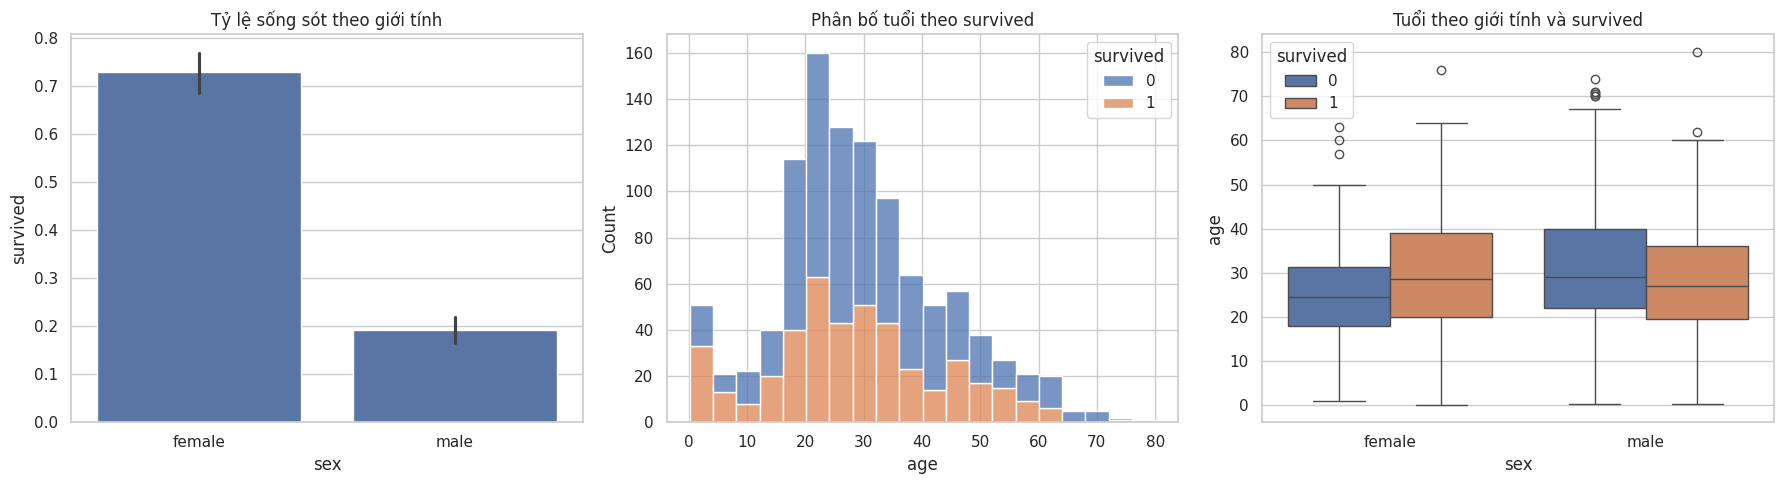

In [6]:
print("Hồng Kim Dung - 6451071009")

fig, ax = plt.subplots(1, 3, figsize=(18,5))
sns.barplot(data=df, x="sex", y="survived", ax=ax[0]); ax[0].set_title("Tỷ lệ sống sót theo giới tính")
sns.histplot(data=df, x="age", hue="survived", multiple="stack", bins=20, ax=ax[1]); ax[1].set_title("Phân bố tuổi theo survived")
sns.boxplot(data=df, x="sex", y="age", hue="survived", ax=ax[2]); ax[2].set_title("Tuổi theo giới tính và survived")
plt.tight_layout(); plt.show()

Hồng Kim Dung - 6451071009


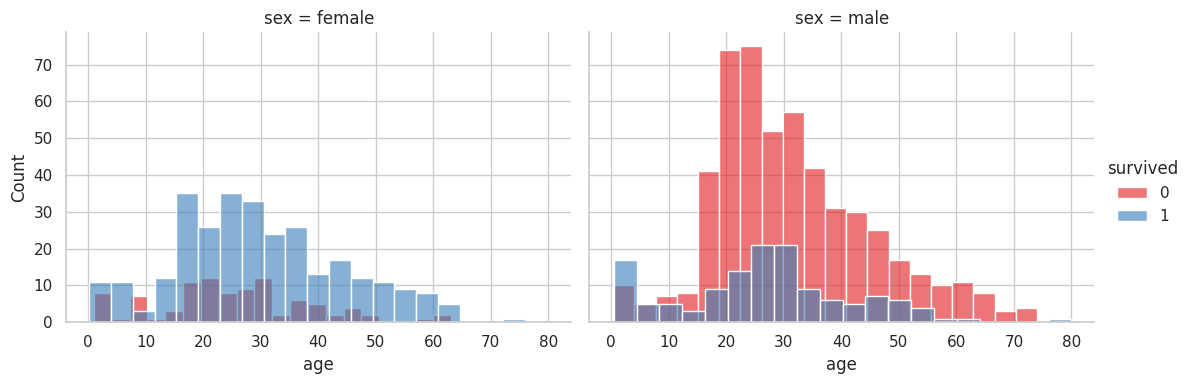

sex
female    0.727
male      0.191
Name: survived, dtype: float64


In [7]:
print("Hồng Kim Dung - 6451071009")

g = sns.FacetGrid(df, col="sex", hue="survived", height=4, aspect=1.4, palette="Set1")
g.map(sns.histplot, "age", bins=20, alpha=.6).add_legend(); plt.show()
print(df.groupby("sex")["survived"].mean().round(3))

**Nhận xét:** nữ có tỷ lệ sống sót cao hơn hẳn nam (72,7% so với 19,1%). Về tuổi, nhóm trẻ em dưới 10 tuổi sống sót nhiều nhất (khoảng 58%), các nhóm 10-60 tuổi dao động quanh 37-48%, nhóm trên 60 tuổi thấp nhất (khoảng 24%). Như vậy giới tính ảnh hưởng mạnh hơn tuổi, và chính sách ưu tiên phụ nữ, trẻ em thể hiện rõ trong dữ liệu.

## Câu 4: Liên quan giữa embarked, pclass và survived, phân biệt theo sex

Hồng Kim Dung - 6451071009


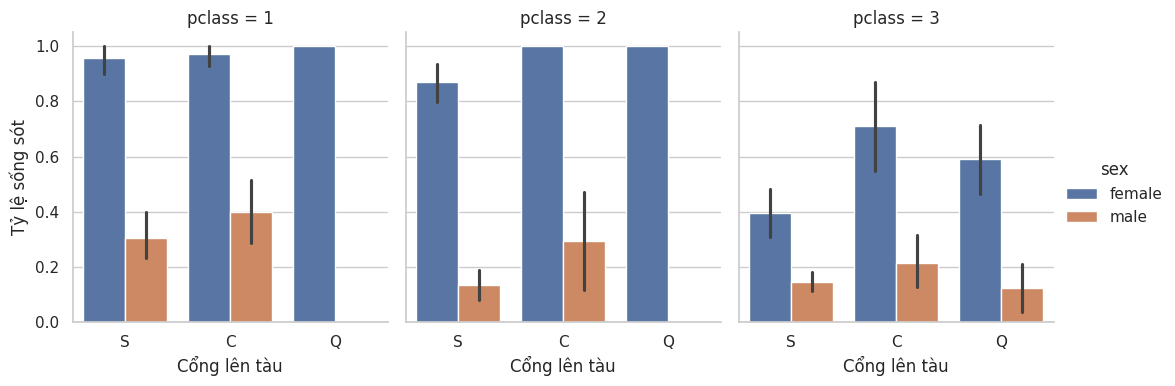

In [8]:
print("Hồng Kim Dung - 6451071009")

g = sns.catplot(data=df, x="embarked", y="survived", hue="sex", col="pclass", kind="bar", height=4, aspect=.9)
g.set_axis_labels("Cổng lên tàu", "Tỷ lệ sống sót"); plt.show()

Hồng Kim Dung - 6451071009


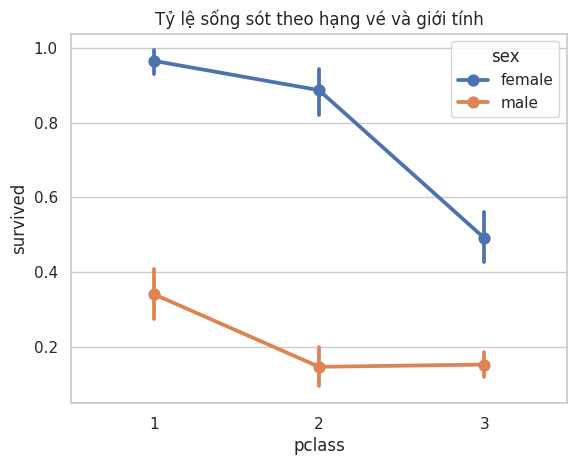

sex              female   male
pclass embarked               
1      C          0.972  0.400
       Q          1.000  0.000
       S          0.957  0.306
2      C          1.000  0.294
       Q          1.000  0.000
       S          0.871  0.134
3      C          0.710  0.214
       Q          0.589  0.123
       S          0.395  0.145


In [9]:
print("Hồng Kim Dung - 6451071009")

sns.pointplot(data=df, x="pclass", y="survived", hue="sex"); plt.title("Tỷ lệ sống sót theo hạng vé và giới tính"); plt.show()
print(df.pivot_table(values="survived", index=["pclass","embarked"], columns="sex", aggfunc="mean").round(3))

**Nhận xét:** hạng vé càng cao (pclass càng nhỏ) thì tỷ lệ sống sót càng cao, ở cả hai giới. Nữ hạng 1 sống sót khoảng 96%, hạng 2 khoảng 89%, nhưng hạng 3 giảm mạnh còn khoảng 49%. Nam hạng 1 khoảng 34%, còn hạng 2 và hạng 3 chỉ khoảng 15%. Ở mọi hạng vé, nữ đều sống sót cao hơn nam rất nhiều. Theo cổng lên tàu, nữ lên ở cảng C (Cherbourg) có tỷ lệ sống sót cao (khoảng 97% đến 100% ở hạng 1, 2) và hành khách lên ở cảng C nói chung sống sót nhiều hơn cảng S (Southampton) và Q (Queenstown), một phần do cảng C có nhiều khách hạng 1 hơn. Riêng nam hạng 3 lên ở cảng Q chỉ sống sót khoảng 12%.

## Câu 5: Số người đi cùng (sibsp, parch) và survived

Hồng Kim Dung - 6451071009


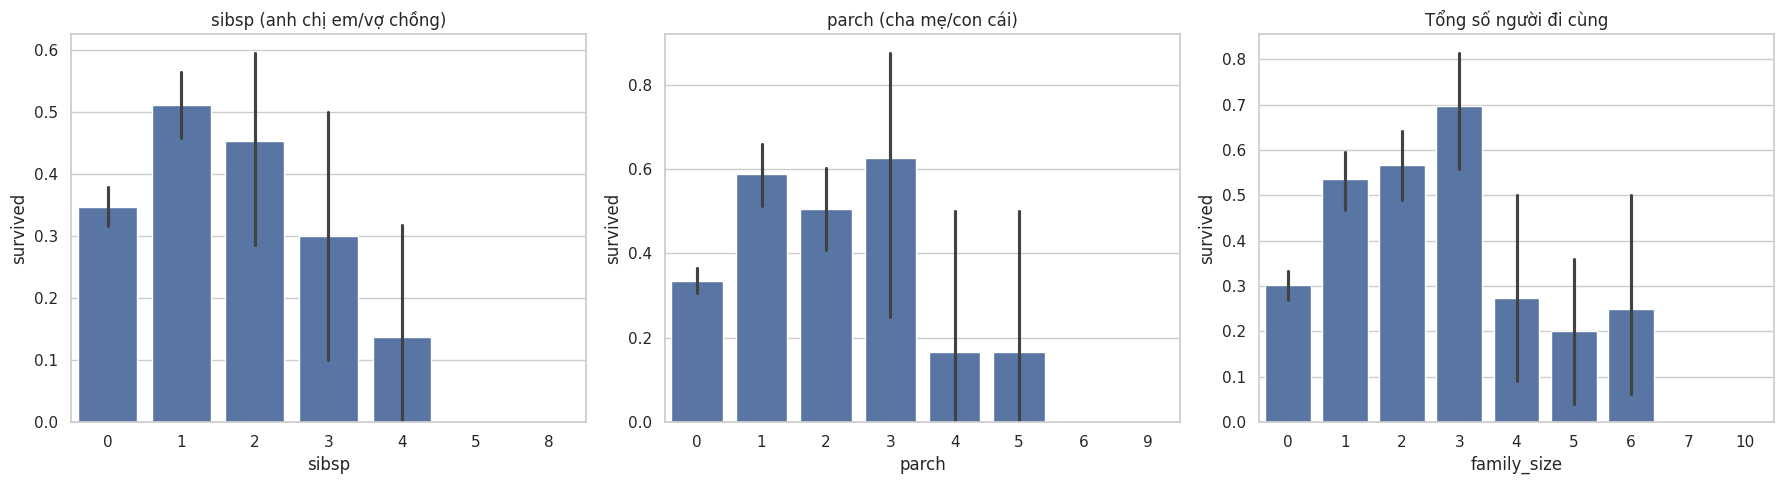

In [10]:
print("Hồng Kim Dung - 6451071009")

df["family_size"] = df["sibsp"] + df["parch"]
fig, ax = plt.subplots(1, 3, figsize=(18,5))
sns.barplot(data=df, x="sibsp", y="survived", ax=ax[0]); ax[0].set_title("sibsp (anh chị em/vợ chồng)")
sns.barplot(data=df, x="parch", y="survived", ax=ax[1]); ax[1].set_title("parch (cha mẹ/con cái)")
sns.barplot(data=df, x="family_size", y="survived", ax=ax[2]); ax[2].set_title("Tổng số người đi cùng")
plt.tight_layout(); plt.show()

In [11]:
print("Hồng Kim Dung - 6451071009")
print(df["family_size"].value_counts().sort_index())
df.groupby("family_size")["survived"].agg(["count","mean"]).round(3)

Hồng Kim Dung - 6451071009
family_size
0     790
1     235
2     159
3      43
4      22
5      25
6      16
7       8
10     11
Name: count, dtype: int64


,count,mean
family_size,,
0,790,0.303
1,235,0.536
2,159,0.566
3,43,0.698
4,22,0.273
5,25,0.200
6,16,0.250
7,8,0.000
10,11,0.000


**Nhận xét:** phần lớn hành khách đi một mình (790 người) và có tỷ lệ sống sót thấp, khoảng 30%. Đi cùng 1-3 người thân thì tỷ lệ sống sót cao hơn rõ rệt (từ 54% đến 70%, cao nhất khi đi cùng 3 người). Từ 4 người thân trở lên, tỷ lệ sống sót giảm mạnh (khoảng 0-27%), và các gia đình đi cùng 7 người trở lên không ai sống sót. Điều này cho thấy đi cùng gia đình nhỏ có lợi, còn gia đình quá đông thì khó thoát hơn.

## Câu 6: Tiền xử lý thuộc tính thiếu dữ liệu và xóa thuộc tính không cần thiết

In [12]:
print("Hông Kim Dung - 6451071009")

df["title"] = df["name"].str.extract(r" ([A-Za-z]+)\.", expand=False)

# Điền tuổi bằng trung vị theo (pclass, sex); embarked bằng giá trị phổ biến; fare bằng trung vị
df["age"] = df["age"].fillna(df.groupby(["pclass","sex"])["age"].transform("median"))
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["fare"] = df["fare"].fillna(df["fare"].median())

# Xóa các thuộc tính không cần thiết
df = df.drop(columns=["cabin","boat","body","home.dest","ticket"], errors="ignore")
print(df.isnull().sum())
df.head()

Hông Kim Dung - 6451071009
pclass         0
survived       0
name           0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
family_size    0
title          0
dtype: int64


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,family_size,title
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,211.3375,S,0,Miss
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,151.5500,S,3,Master
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,151.5500,S,3,Miss
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,151.5500,S,3,Mr
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,151.5500,S,3,Mrs


**Nhận xét:** `cabin`, `boat`, `body` thiếu quá nhiều, `boat`/`body` còn gây rò rỉ nhãn (chỉ có khi sống sót / tử vong), `home.dest` và `ticket` ít giá trị dự đoán nên bị xóa. `age`, `embarked`, `fare` được điền giá trị.

## Câu 7: Biến đổi thuộc tính

In [13]:
print("Hồng Kim Dung - 6451071009")
df["title"] = df["name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
# 7.1 fare -> kiểu nguyên
df["fare"] = df["fare"].astype(int)

# 7.2 title
print(df["title"].value_counts())
df["title"] = df["title"].replace({"Mlle":"Miss","Ms":"Miss","Mme":"Mrs"})
df["title"] = df["title"].where(df["title"].isin(["Mr","Mrs","Miss","Master"]), "Rare")
print(df["title"].value_counts())

Hồng Kim Dung - 6451071009
title
Mr          757
Miss        260
Mrs         197
Master       61
Dr            8
Rev           8
Col           4
Major         2
Mlle          2
Ms            2
Lady          1
Capt          1
Mme           1
Sir           1
Jonkheer      1
Dona          1
Don           1
Countess      1
Name: count, dtype: int64
title
Mr        757
Miss      264
Mrs       198
Master     61
Rare       29
Name: count, dtype: int64


In [14]:
print("Hồng Kim Dung - 6451071009")

# 7.3 sex, embarked -> số
df["sex"] = df["sex"].map({"male":0, "female":1})
df["embarked"] = df["embarked"].map({"S":0, "C":1, "Q":2})
df[["sex","embarked"]].head()

Hồng Kim Dung - 6451071009


,sex,embarked
0,1,0
1,0,0
2,1,0
3,0,0
4,1,0


In [15]:
print("Hồng Kim Dung - 6451071009")

# 7.4 Chia age thành 8 nhóm theo gợi ý
age_bins = [-np.inf, 11, 18, 22, 27, 33, 40, 66, np.inf]
df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=range(1,9)).astype(int)
print(df["age_group"].value_counts().sort_index())

# 7.5 Chia fare thành 6 nhóm theo gợi ý
fare_bins = [-np.inf, 7.91, 14.454, 31, 99, 250, np.inf]
df["fare_group"] = pd.cut(df["fare"], bins=fare_bins, labels=range(1,7)).astype(int)
print(df["fare_group"].value_counts().sort_index())

Hồng Kim Dung - 6451071009
age_group
1     90
2    103
3    204
4    315
5    195
6    147
7    246
8      9
Name: count, dtype: int64
fare_group
1    360
2    313
3    325
4    227
5     67
6     17
Name: count, dtype: int64


**Nhận xét**: fare đã chuyển sang số nguyên, sex và embarked đã thành số, title được rút gọn còn 5 loại (Mr, Mrs, Miss, Master, Rare). Age được chia thành 8 nhóm và fare thành 6 nhóm theo mốc gợi ý (cột mới age_group, fare_group, giữ nguyên cột gốc). Các nhóm tuổi 3 đến 7 và các nhóm giá vé 1 đến 4 tương đối cân bằng (khoảng 150-360 người mỗi nhóm), còn nhóm tuổi 8 (trên 66 tuổi, 9 người) và nhóm giá vé 6 (trên 250, 17 người) rất ít do ít hành khách ở khoảng giá trị cực đoan này.

## Câu 8: Tạo thuộc tính mới

In [16]:
print("Hồng Kim Dung - 6451071009")

df["age_class"] = df["age"] * df["pclass"]
df["fare_per_person"] = df["fare"] / (df["sibsp"] + df["parch"] + 1)   # +1 để tính cả bản thân, tránh chia cho 0
df[["age","pclass","age_class","fare","sibsp","parch","fare_per_person"]].head(10)

Hồng Kim Dung - 6451071009


,age,pclass,age_class,fare,sibsp,parch,fare_per_person
0,29.0000,1,29.0000,211,0,0,211.00
1,0.9167,1,0.9167,151,1,2,37.75
2,2.0000,1,2.0000,151,1,2,37.75
3,30.0000,1,30.0000,151,1,2,37.75
4,25.0000,1,25.0000,151,1,2,37.75
5,48.0000,1,48.0000,26,0,0,26.00
6,63.0000,1,63.0000,77,1,0,38.50
7,39.0000,1,39.0000,0,0,0,0.00
8,53.0000,1,53.0000,51,2,0,17.00
9,71.0000,1,71.0000,49,0,0,49.00


In [17]:
print("Hồng Kim Dung - 6451071009")
df.head(12)

Hồng Kim Dung - 6451071009


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,family_size,title,age_group,fare_group,age_class,fare_per_person
0,1,1,"Allen, Miss. Elisabeth Walton",1,29.0000,0,0,211,0,0,Miss,5,5,29.0000,211.00
1,1,1,"Allison, Master. Hudson Trevor",0,0.9167,1,2,151,0,3,Master,1,5,0.9167,37.75
2,1,0,"Allison, Miss. Helen Loraine",1,2.0000,1,2,151,0,3,Miss,1,5,2.0000,37.75
3,1,0,"Allison, Mr. Hudson Joshua Creighton",0,30.0000,1,2,151,0,3,Mr,5,5,30.0000,37.75
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",1,25.0000,1,2,151,0,3,Mrs,4,5,25.0000,37.75
5,1,1,"Anderson, Mr. Harry",0,48.0000,0,0,26,0,0,Mr,7,3,48.0000,26.00
6,1,1,"Andrews, Miss. Kornelia Theodosia",1,63.0000,1,0,77,0,1,Miss,7,4,63.0000,38.50
7,1,0,"Andrews, Mr. Thomas Jr",0,39.0000,0,0,0,0,0,Mr,6,1,39.0000,0.00
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",1,53.0000,2,0,51,0,2,Mrs,7,4,53.0000,17.00
9,1,0,"Artagaveytia, Mr. Ramon",0,71.0000,0,0,49,1,0,Mr,8,4,71.0000,49.00
